In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import t
from matplotlib import pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [3]:
def func_1(x, a, b):
    return a * x ** b

In [4]:
def fitting(X, Y):
    popt, pcov = curve_fit(func_1, X, Y)
    a, b = popt
    y_pred = func_1(X, a, b)
    r2 = r2_score(Y, y_pred)
    x_sim = np.linspace(min(X), max(X), 100)
    y_sim = func_1(x_sim, a, b)
    dof = len(X) - len(popt)

    return a, b, r2, x_sim, y_sim, popt, pcov, dof


def conf_band(x, popt, pcov, dof, alpha=0.05):
    """95% confidence band of the fitted power law A = a * E**b, propagated from the
    curve_fit parameter covariance via the delta method. This is the SAME construction
    as predict_interval() in notebook 6 (mining-area estimation), so the figure, its
    caption, and the uncertainty propagation stay mutually consistent."""
    a, b = popt
    f = a * x ** b
    df_da = x ** b
    df_db = a * x ** b * np.log(x)
    var = pcov[0, 0] * df_da ** 2 + 2 * pcov[0, 1] * df_da * df_db + pcov[1, 1] * df_db ** 2
    se = np.sqrt(var)
    tval = t.ppf(1 - alpha / 2, dof)
    return f - tval * se, f + tval * se

In [5]:
DF_1 = pd.read_csv(RESULTS / 'extraction-area-relationship.csv')

X = DF_1['E (Mt)'].values
Y = DF_1['A (ha)'].values
a, b, r2, x_sim, y_sim, popt, pcov, dof = fitting(X, Y)
y_lo, y_hi = conf_band(x_sim, popt, pcov, dof)

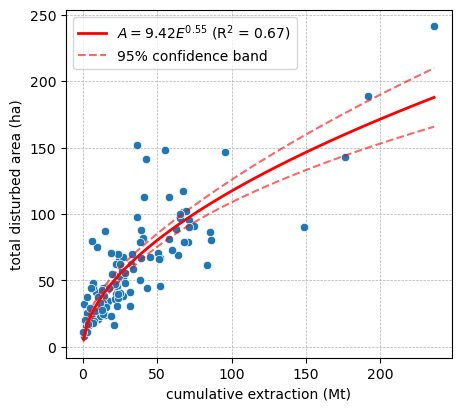

In [8]:
fig = plt.figure(figsize=(4.5, 4), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1)
sns.scatterplot(x=X, y=Y, zorder=3)
ax1.plot(x_sim, y_sim, lw=2.0, color='r', label=f'$A={a:.2f}E^{{{b:.2f}}}$ (R$^{2}$ = {round(r2, 2)})', zorder=5)
ax1.plot(x_sim, y_lo, ls='--', c='r', alpha=0.6, zorder=5)
ax1.plot(x_sim, y_hi, ls='--', c='r', alpha=0.6, zorder=5, label='95% confidence band')
ax1.grid('on', ls='--', lw=0.5)
ax1.legend(loc='best', fontsize=10)
ax1.set(xlabel='cumulative extraction (Mt)', ylabel='total disturbed area (ha)')

plt.show()
fig.savefig(FIGURES / 'Supplementary-Figure-14.jpg', dpi=600, bbox_inches='tight')